
=== Granger Causality - SSP1-2.6 (% of edges) ===
          New (+)  New (−)  Lost (+)  Lost (−)  Sign flip  Strengthened  Weakened  Stable
TROP-JJA     29.2      0.0      54.2       0.0        0.0          12.5       0.0     4.2
TROP-DJF     28.6      0.0      62.9       0.0        0.0           0.0       8.6     0.0
NSZ-JJA      45.0      0.0      50.0       0.0        0.0           5.0       0.0     0.0
NSZ-DJF      36.0      0.0      56.0       0.0        0.0           4.0       4.0     0.0
SSZ-JJA      42.1      0.0      52.6       0.0        0.0           0.0       0.0     5.3
SSZ-DJF      53.3      0.0      46.7       0.0        0.0           0.0       0.0     0.0
NMZ-JJA      20.0      0.0      80.0       0.0        0.0           0.0       0.0     0.0
NMZ-DJF      50.0      0.0      41.7       0.0        0.0           0.0       8.3     0.0
SMZ-JJA      72.2      0.0      22.2       0.0        0.0           5.6       0.0     0.0
SMZ-DJF      50.0      0.0      42.9       0.0   

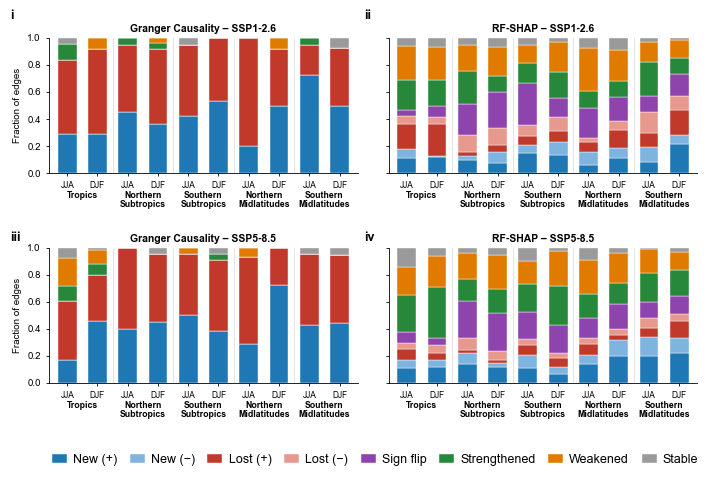

In [5]:
import pandas as pd
import numpy as np
import matplotlib
# NOTE: 'Agg' removed so the figure can be previewed with plt.show()
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm

# ---- Nature Communications style ----
available = {f.name for f in fm.fontManager.ttflist}
for candidate in ['Arial', 'Liberation Sans', 'Helvetica', 'DejaVu Sans']:
    if candidate in available:
        plt.rcParams['font.family'] = candidate
        break
plt.rcParams['font.size'] = 7
plt.rcParams['axes.linewidth'] = 0.6
plt.rcParams['xtick.major.width'] = 0.6
plt.rcParams['ytick.major.width'] = 0.6
plt.rcParams['pdf.fonttype'] = 42
plt.rcParams['svg.fonttype'] = 'none'

base = '/Users/dianindrawati/Documents/Python/CMIP6_and_ERA5'

# ---- Load data ----
df = pd.read_excel(f'{base}/Fraction_interdependence_change.xlsx', header=None, skiprows=2)
df.columns = ['RegionSeason', 'Code', 'Label', 'GC126', 'RFSHAP126', 'GC585', 'RFSHAP585']
df[['Region', 'Season']] = df['RegionSeason'].str.split('-', expand=True)

region_order = ['TROP', 'NSZ', 'SSZ', 'NMZ', 'SMZ']
region_names = {
    'TROP': 'Tropics',
    'NSZ':  'Northern\nSubtropics',
    'SSZ':  'Southern\nSubtropics',
    'NMZ':  'Northern\nMidlatitudes',
    'SMZ':  'Southern\nMidlatitudes'
}
season_order = ['JJA', 'DJF']
group_order = [f'{r}-{s}' for r in region_order for s in season_order]

code_order = ['NP', 'NN', 'LP', 'LN', 'SF', 'S', 'W', 'ST']
code_labels = {
    'NP': 'New (+)', 'NN': 'New (\u2212)',
    'LP': 'Lost (+)', 'LN': 'Lost (\u2212)',
    'SF': 'Sign flip', 'S': 'Strengthened',
    'W': 'Weakened', 'ST': 'Stable'
}
# LaTeX-safe versions of the labels (unicode minus -> math minus)
code_labels_tex = {
    'NP': 'New ($+$)', 'NN': 'New ($-$)',
    'LP': 'Lost ($+$)', 'LN': 'Lost ($-$)',
    'SF': 'Sign flip', 'S': 'Strength.',
    'W': 'Weak.', 'ST': 'Stable'
}

colors = {
    'NP': '#1f77b4', 'NN': '#7fb3e0',
    'LP': '#c0392b', 'LN': '#e8998d',
    'SF': '#8e44ad',
    'S':  '#27883b',
    'W':  '#e07b00',
    'ST': '#9a9a9a',
}

panels = [
    ('GC126', 'Granger Causality', 'SSP1-2.6'),
    ('RFSHAP126', 'RF-SHAP', 'SSP1-2.6'),
    ('GC585', 'Granger Causality', 'SSP5-8.5'),
    ('RFSHAP585', 'RF-SHAP', 'SSP5-8.5'),
]

# ---- Build fraction table: rows=group, cols=code ----
def get_fracs(col):
    mat = np.zeros((len(group_order), len(code_order)))
    for gi, g in enumerate(group_order):
        sub = df[df['RegionSeason'] == g].set_index('Code')[col]
        total = sub.sum()
        for ci, c in enumerate(code_order):
            mat[gi, ci] = sub.get(c, 0) / total if total > 0 else 0
    return mat

fracs = {col: get_fracs(col) for col, _, _ in panels}

# ---- Figure: 180 mm wide (double column), 4 panels 2x2 ----
mm = 1 / 25.4
fig, axes = plt.subplots(2, 2, figsize=(180 * mm, 120 * mm), sharey=True)

x = np.arange(len(group_order))
bar_w = 0.62

for ax, (col, method_name, scen_name) in zip(axes.flat, panels):
    mat = fracs[col]
    bottom = np.zeros(len(group_order))
    for ci, c in enumerate(code_order):
        ax.bar(x, mat[:, ci], bottom=bottom, width=bar_w,
               color=colors[c], edgecolor='white', linewidth=0.3,
               label=code_labels[c], zorder=3)
        bottom += mat[:, ci]

    ax.set_title(f'{method_name} \u2013 {scen_name}', fontsize=7.5, fontweight='bold', pad=4)
    ax.set_ylim(0, 1.0)
    ax.set_xlim(-0.6, len(group_order) - 0.4)
    ax.set_xticks(x)
    ax.set_xticklabels([g.split('-')[1] for g in group_order], fontsize=6)
    ax.tick_params(axis='both', length=2.5)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

    for ridx, r in enumerate(region_order):
        cx = ridx * 2 + 0.5
        #ax.text(cx, -0.135, r, ha='center', va='top', fontsize=6.3,
        #        fontweight='bold', transform=ax.get_xaxis_transform(), clip_on=False)
        ax.text(cx, -0.135, region_names[r], ha='center', va='top', fontsize=6.3,
        fontweight='bold', linespacing=0.95,
        transform=ax.get_xaxis_transform(), clip_on=False)

        if ridx > 0:
            ax.axvline(ridx * 2 - 0.5, color='0.85', lw=0.5, zorder=1)

for ax in axes[:, 0]:
    ax.set_ylabel('Fraction of edges', fontsize=7)

fig.subplots_adjust(left=0.07, right=0.985, top=0.93, bottom=0.2, wspace=0.10, hspace=0.55)

handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc='lower center', ncol=8, frameon=False,
           fontsize=9, bbox_to_anchor=(0.53, 0.0), columnspacing=1.0,
           handlelength=1.2, handletextpad=0.5)

fig.text(0.015, 0.97, 'i', fontsize=9, fontweight='bold')
fig.text(0.515, 0.97, 'ii', fontsize=9, fontweight='bold')
fig.text(0.015, 0.50, 'iii', fontsize=9, fontweight='bold')
fig.text(0.515, 0.50, 'iv', fontsize=9, fontweight='bold')

# PNG for quick viewing, PDF (vector) for Overleaf
fig.savefig(f'{base}/network_change_fraction.png', dpi=800)
fig.savefig(f'{base}/network_change_fraction.pdf')

# =====================================================================
# Results for Overleaf
# =====================================================================

# ---- 1. Console preview (plain text) ----
for col, method_name, scen_name in panels:
    tab = pd.DataFrame(fracs[col] * 100, index=group_order,
                       columns=[code_labels[c] for c in code_order]).round(1)
    print(f'\n=== {method_name} - {scen_name} (% of edges) ===')
    print(tab.to_string())

# ---- 2. LaTeX table (booktabs) ----
def build_latex_table():
    ncol = 2 + len(code_order)
    L = []
    L.append(r'\begin{table*}[ht]')
    L.append(r'\centering')
    L.append(r'\caption{Fraction (\%) of network edges in each change category, '
             r'by region and season, for Granger causality (GC) and RF-SHAP under '
             r'SSP1-2.6 and SSP5-8.5.}')
    L.append(r'\label{tab:network_change_fraction}')
    L.append(r'\small')
    L.append(r'\setlength{\tabcolsep}{4pt}')
    L.append(r'\begin{tabular}{ll' + 'r' * len(code_order) + '}')
    L.append(r'\toprule')
    L.append('Region & Season & ' + ' & '.join(code_labels_tex[c] for c in code_order) + r' \\')
    for col, method_name, scen_name in panels:
        mat = fracs[col] * 100
        L.append(r'\midrule')
        L.append(rf'\multicolumn{{{ncol}}}{{l}}{{\textbf{{{method_name} -- {scen_name}}}}} \\')
        L.append(r'\midrule')
        for gi, g in enumerate(group_order):
            region, season = g.split('-')
            region_cell = region if season == season_order[0] else ''
            vals = ' & '.join(f'{v:.1f}' for v in mat[gi])
            L.append(f'{region_cell} & {season} & {vals} \\\\')
            if season == season_order[-1] and region != region_order[-1]:
                L.append(r'\addlinespace[2pt]')
    L.append(r'\bottomrule')
    L.append(r'\end{tabular}')
    L.append(r'\end{table*}')
    return '\n'.join(L)

latex_table = build_latex_table()

# ---- 3. LaTeX figure block ----
latex_figure = r'''\begin{figure*}[ht]
\centering
\includegraphics[width=\textwidth]{network_change_fraction.pdf}
\caption{Fraction of network edges by change category for each region and season.
\textbf{a}, Granger causality, SSP1-2.6. \textbf{b}, RF-SHAP, SSP1-2.6.
\textbf{c}, Granger causality, SSP5-8.5. \textbf{d}, RF-SHAP, SSP5-8.5.}
\label{fig:network_change_fraction}
\end{figure*}'''

print('\n% ---------------- Copy into Overleaf ----------------')
print('% Preamble needs: \\usepackage{booktabs, graphicx}')
print(latex_figure)
print()
print(latex_table)

with open(f'{base}/network_change_fraction_table.tex', 'w') as f:
    f.write(latex_table)
with open(f'{base}/network_change_fraction_figure.tex', 'w') as f:
    f.write(latex_figure)

print('\ndone')
plt.show()   # interactive preview


=== Granger causality (% of edges) ===
     New (+)  New (−)  Lost (+)  Lost (−)  Sign flip  Strengthened  Weakened  Stable   n
T       36.5      0.0      54.1       0.0        0.0           3.5       5.9     0.0  85
Prw     56.5      0.0      37.6       0.0        0.0           1.2       4.7     0.0  85
Pr      47.5      0.0      42.6       0.0        0.0           1.6       3.3     4.9  61
ET      54.1      0.0      42.6       0.0        0.0           1.6       1.6     0.0  61
SM      48.4      0.0      36.8       0.0        0.0           9.5       5.3     0.0  95
q       47.2      0.0      40.4       0.0        0.0           3.4       7.9     1.1  89

=== RF-SHAP (% of edges) ===
     New (+)  New (−)  Lost (+)  Lost (−)  Sign flip  Strengthened  Weakened  Stable    n
T        6.5      8.3       5.1       9.7       17.0          28.2      20.9     4.3  277
Prw     12.2      3.6       8.3       3.2       15.1          24.5      24.5     8.6  278
Pr      10.6      1.0       7.6      

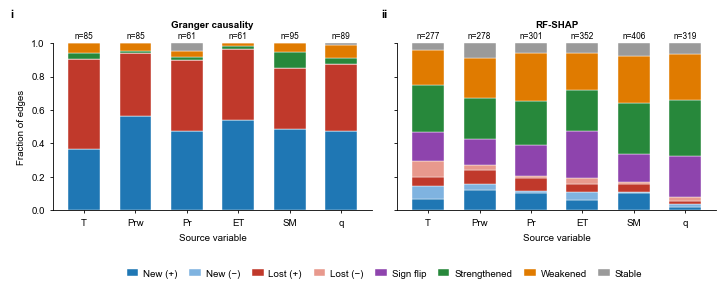

In [7]:
# each variable globally

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm

# =====================================================================
# Settings (edit here)
# =====================================================================
base = '/Users/dianindrawati/Documents/Python/CMIP6_and_ERA5'
csv_file = f'{base}/Fig5_edge_change_fractions_variable_by_category.csv'
out_stem = f'{base}/Fig5_edge_change_by_variable'

# x-axis order and display labels for the source variable
var_order = ['T', 'Prw', 'Pr', 'ET', 'SM', 'q']
var_labels = {'T': 'T', 'q': 'q', 'Prw': 'Prw', 'Pr': 'Pr', 'SM': 'SM', 'ET': 'ET'}

# ---- Nature style: 7 pt, Liberation Sans/Arial, 600 dpi, 183 mm ----
available = {f.name for f in fm.fontManager.ttflist}
for candidate in ['Liberation Sans', 'Arial', 'Helvetica', 'DejaVu Sans']:
    if candidate in available:
        plt.rcParams['font.family'] = candidate
        break
plt.rcParams.update({
    'font.size': 7, 'axes.labelsize': 7, 'axes.titlesize': 7,
    'xtick.labelsize': 7, 'ytick.labelsize': 7, 'legend.fontsize': 7,
    'axes.linewidth': 0.6, 'xtick.major.width': 0.6, 'ytick.major.width': 0.6,
    'pdf.fonttype': 42, 'svg.fonttype': 'none',
})

# =====================================================================
# Load data (drop the stray helper columns/rows at the end of the CSV)
# =====================================================================
cat_cols = ['new_positive', 'new_negative', 'lost_positive', 'lost_negative',
            'sign_changed', 'strengthened', 'weakened', 'stable']
df = pd.read_csv(csv_file, usecols=['method', 'source'] + cat_cols)
df = df.dropna(subset=['method', 'source'])
df['method'] = df['method'].str.strip().str.lower()
df['source'] = df['source'].str.strip()
df[cat_cols] = df[cat_cols].fillna(0).astype(int)

code_labels = {
    'new_positive': 'New (+)', 'new_negative': 'New (\u2212)',
    'lost_positive': 'Lost (+)', 'lost_negative': 'Lost (\u2212)',
    'sign_changed': 'Sign flip', 'strengthened': 'Strengthened',
    'weakened': 'Weakened', 'stable': 'Stable',
}
code_labels_tex = {
    'new_positive': 'New ($+$)', 'new_negative': 'New ($-$)',
    'lost_positive': 'Lost ($+$)', 'lost_negative': 'Lost ($-$)',
    'sign_changed': 'Sign flip', 'strengthened': 'Strength.',
    'weakened': 'Weak.', 'stable': 'Stable',
}
colors = {
    'new_positive': '#1f77b4', 'new_negative': '#7fb3e0',
    'lost_positive': '#c0392b', 'lost_negative': '#e8998d',
    'sign_changed': '#8e44ad', 'strengthened': '#27883b',
    'weakened': '#e07b00', 'stable': '#9a9a9a',
}

panels = [('granger', 'Granger causality'), ('shap', 'RF-SHAP')]

# ---- counts and fractions: rows = variable, cols = category ----
def get_counts(method):
    sub = df[df['method'] == method].set_index('source')
    return sub.reindex(var_order)[cat_cols].fillna(0).to_numpy(dtype=float)

counts = {m: get_counts(m) for m, _ in panels}
totals = {m: counts[m].sum(axis=1) for m, _ in panels}
fracs = {m: np.divide(counts[m], totals[m][:, None],
                      out=np.zeros_like(counts[m]), where=totals[m][:, None] > 0)
         for m, _ in panels}

# =====================================================================
# Figure: 183 mm (double column), 1 x 2 panels
# =====================================================================
mm = 1 / 25.4
fig, axes = plt.subplots(1, 2, figsize=(183 * mm, 72 * mm), sharey=True)

x = np.arange(len(var_order))
bar_w = 0.62

for ax, (m, method_name) in zip(axes, panels):
    mat = fracs[m]
    bottom = np.zeros(len(var_order))
    for ci, c in enumerate(cat_cols):
        ax.bar(x, mat[:, ci], bottom=bottom, width=bar_w,
               color=colors[c], edgecolor='white', linewidth=0.3,
               label=code_labels[c], zorder=3)
        bottom += mat[:, ci]

    # number of edges above each bar
    for xi, n in zip(x, totals[m]):
        ax.text(xi, 1.015, f'n={int(n)}', ha='center', va='bottom', fontsize=6)

    ax.set_title(method_name, fontweight='bold', pad=11)
    ax.set_ylim(0, 1.0)
    ax.set_xlim(-0.6, len(var_order) - 0.4)
    ax.set_xticks(x)
    ax.set_xticklabels([var_labels[v] for v in var_order])
    ax.set_yticks(np.arange(0, 1.01, 0.2))
    ax.tick_params(axis='both', length=2.5)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.set_xlabel('Source variable')

axes[0].set_ylabel('Fraction of edges')

fig.subplots_adjust(left=0.07, right=0.99, top=0.86, bottom=0.27, wspace=0.08)

handles, labels = axes[1].get_legend_handles_labels()
fig.legend(handles, labels, loc='lower center', ncol=8, frameon=False,
           bbox_to_anchor=(0.53, 0.0), columnspacing=1.2,
           handlelength=1.2, handletextpad=0.5)

fig.text(0.01, 0.95, 'i', fontsize=8, fontweight='bold')
fig.text(0.525, 0.95, 'ii', fontsize=8, fontweight='bold')

fig.savefig(f'{out_stem}.png', dpi=600)
fig.savefig(f'{out_stem}.pdf')

# =====================================================================
# Console preview + LaTeX table
# =====================================================================
for m, method_name in panels:
    tab = pd.DataFrame(fracs[m] * 100, index=var_order,
                       columns=[code_labels[c] for c in cat_cols]).round(1)
    tab['n'] = totals[m].astype(int)
    print(f'\n=== {method_name} (% of edges) ===')
    print(tab.to_string())

def build_latex_table():
    ncol = 2 + len(cat_cols)
    L = [r'\begin{table*}[ht]', r'\centering',
         r'\caption{Fraction (\%) of network edges in each change category, by '
         r'source variable, for Granger causality and RF-SHAP. $n$ is the total '
         r'number of edges per variable.}',
         r'\label{tab:edge_change_by_variable}', r'\small',
         r'\setlength{\tabcolsep}{4pt}',
         r'\begin{tabular}{l' + 'r' * len(cat_cols) + 'r}', r'\toprule',
         'Variable & ' + ' & '.join(code_labels_tex[c] for c in cat_cols) + r' & $n$ \\']
    for m, method_name in panels:
        L += [r'\midrule',
              rf'\multicolumn{{{ncol}}}{{l}}{{\textbf{{{method_name}}}}} \\',
              r'\midrule']
        for vi, v in enumerate(var_order):
            vals = ' & '.join(f'{p:.1f}' for p in fracs[m][vi] * 100)
            L.append(f'{var_labels[v]} & {vals} & {int(totals[m][vi])} \\\\')
    L += [r'\bottomrule', r'\end{tabular}', r'\end{table*}']
    return '\n'.join(L)

latex_table = build_latex_table()
with open(f'{out_stem}_table.tex', 'w') as f:
    f.write(latex_table)
print('\n' + latex_table)
print('\ndone')
plt.show()